# Etapa II · Fase 2 · Bloque C-2: efecto de la normalización

**Pregunta del bloque:** ¿cuánto limpiar el texto ayuda a clasificar? ¿Y le conviene lo mismo a los tres modelos?

| | |
|---|---|
| **Factor que cambia** | La normalización: N0, N1, N2 |
| **Fijo** | TF-IDF, unigramas `(1,1)`, sin SVD, misma rejilla de hiperparámetros que C-1 |
| **Experimentos** | 3 normalizaciones × 3 modelos = 9 |
| **Selección** | Cada modelo se queda con **su** mejor normalización (macro-F1 en dev; si hay empate, la de mayor CV) |

N2 con TF-IDF (1,1) es exactamente la configuración de C-1, así que esas tres filas **no se duplican**: se reutilizan C01-C03. Los experimentos nuevos son C04-C09.

## 1. Justificación del bloque

### Por qué se prueba la normalización
La normalización decide **qué cuenta como la misma palabra**. Eso cambia el tamaño del vocabulario y cuánta evidencia acumula cada término:
- Si `Models`, `models` y `model` son tres rasgos distintos, la evidencia de que un abstract habla de modelos se reparte en tres columnas.
- Si se unifican, el rasgo `model` es más fuerte, pero se pierden matices: por ejemplo, el plural, o las mayúsculas de `LLMs` o `RAG`.

El enunciado pide comparar al menos 3 configuraciones, incluida una línea base mínima.

### Qué pone a prueba cada nivel

| ID | Operaciones | Qué se mide frente al nivel anterior |
|---|---|---|
| **N0** | Solo tokenización con spaCy | Línea base: mayúsculas, puntuación y stopwords tal cual |
| **N1** | + minúsculas, sin puntuación, sin stopwords (`is_stop`) | ¿Ayuda quitar ruido? |
| **N2** | + lemas, filtro por POS (Etapa I) | ¿Ayuda además juntar formas de una misma palabra? |

### Por qué lo demás queda fijo
- **TF-IDF (1,1)**: es la configuración de C-1, así que el único cambio es la normalización (un factor a la vez).
- **La misma rejilla** (`min_df`, `alpha` o `C`): cada normalización puede necesitar otro grado de regularización. Ajustar los hiperparámetros en cada caso hace la comparación justa: se compara lo mejor de cada normalización, no una configuración pensada para otra.
- **`lowercase=False` y tokenizador por espacios** en el vectorizador: sin esto, TfidfVectorizer pasaría N0 a minúsculas y le quitaría la puntuación, y el bloque no mediría nada.

### Hipótesis previa
N1 y N2 deberían superar a N0, porque N0 reparte la evidencia entre variantes y tiene mucho ruido (puntuación, artículos). Entre N1 y N2 no hay una expectativa clara: N2 compacta más el vocabulario, pero N1 quita más palabras.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.etapa2 import config
from src.etapa2.classify import run_block_c2, summary, best_per_model, per_class_table, cv_table
from src.etapa2.labels import load_labeled
from src.etapa2.normalization import load_variants
from src.etapa2.tracking import load_experiments, annotate

pd.set_option("display.max_colwidth", 80)
df = load_labeled()
variants = load_variants().set_index("document_id")
train_ids = df.loc[df["split"] == "train", "document_id"]

## 2. Cómo cambia el vocabulario de train con cada normalización

In [2]:
rows = []
for n in config.NORMALIZATIONS:
    docs = variants.loc[train_ids, f"text_{n.lower()}"].str.split()
    dfreq = pd.Series([t for d in docs for t in set(d)]).value_counts()
    rows.append({
        "normalización": n,
        "tokens/doc": round(docs.str.len().mean(), 1),
        "vocabulario": len(dfreq),
        "en 1 solo doc": f"{(dfreq == 1).mean():.0%}",
        "vocabulario con min_df=2": int((dfreq >= 2).sum()),
    })
pd.DataFrame(rows).set_index("normalización")

,tokens/doc,vocabulario,en 1 solo doc,vocabulario con min_df=2
normalización,,,,
N0,254.0,9974,54%,4608
N1,143.0,8098,53%,3814
N2,153.4,6689,55%,3033


In [3]:
# Cómo queda repartida una misma palabra en cada normalización (frecuencia de documento en train)
def doc_freq(variant, terms):
    docs = variants.loc[train_ids, f"text_{variant.lower()}"].str.split().apply(set)
    return {t: int(docs.apply(lambda s: t in s).sum()) for t in terms}

forms = ["Model", "Models", "model", "models", "LLM", "LLMs", "llm", "llms", "retrieval", "Retrieval", "the", ",", "."]
pd.DataFrame({n: doc_freq(n, forms) for n in config.NORMALIZATIONS}).rename_axis("término")

,N0,N1,N2
término,,,
Model,24,0,0
Models,52,0,0
model,182,185,248
models,174,186,33
LLM,63,0,0
LLMs,49,0,0
llm,0,63,67
llms,0,49,43
retrieval,59,69,69


- En **N0**, *model* aparece en 4 formas distintas y *the*, la coma y el punto están en casi todos los documentos.
- En **N1** las formas se reducen a minúsculas, pero *model* y *models* siguen separadas.
- En **N2** se juntan casi todas en `model` y `llm`. Quedan 33 documentos con `models`, porque spaCy no siempre lematiza el plural; por ejemplo, cuando lo etiqueta como nombre propio en un título.
- **El vocabulario baja casi un tercio de N0 a N2** (9 974 → 6 689), pero en las tres normalizaciones más de la mitad de las palabras aparece en un solo documento. Por eso `min_df` sigue importando.

## 3. Ejecución del bloque C-2

In [4]:
results = run_block_c2(df)
res = summary(results).sort_values(["model", "normalization"])
res[["model", "normalization", "best_params", "cv_macro_f1", "cv_std", "dev_accuracy", "dev_macro_f1", "n_features"]].round(4)

,model,normalization,best_params,cv_macro_f1,cv_std,dev_accuracy,dev_macro_f1,n_features
experiment_id,,,,,,,,
C05,LogisticRegression,N0,C=10; min_df=2,0.7442,0.0164,0.7600,0.7602,4608
C08,LogisticRegression,N1,C=0.1; min_df=2,0.7486,0.0263,0.8000,0.7981,3814
C02,LogisticRegression,N2,C=1; min_df=1,0.7675,0.0219,0.8000,0.7993,6689
C04,MultinomialNB,N0,alpha=0.1; min_df=2,0.7306,0.0346,0.7067,0.7046,4608
C07,MultinomialNB,N1,alpha=0.1; min_df=2,0.7612,0.0502,0.7733,0.7745,3814
C01,MultinomialNB,N2,alpha=0.5; min_df=2,0.7594,0.0213,0.7600,0.7607,3033
C06,SVC,N0,C=10; min_df=1,0.7451,0.0295,0.7733,0.7742,9974
C09,SVC,N1,C=1; min_df=1,0.7487,0.0271,0.7600,0.7613,8098
C03,SVC,N2,C=1; min_df=1,0.7478,0.0334,0.7467,0.7481,6689


### macro-F1 por modelo y normalización

In [5]:
dev = res.pivot(index="model", columns="normalization", values="dev_macro_f1")
cv = res.pivot(index="model", columns="normalization", values="cv_macro_f1")
std = res.pivot(index="model", columns="normalization", values="cv_std")
print("dev (75 documentos; 1 documento ≈ 1.3 puntos):")
display(dev.round(3).style.highlight_max(axis=1, props="font-weight:bold"))
print("CV en train (media de 5 particiones):")
display(cv.round(3).style.highlight_max(axis=1, props="font-weight:bold"))

dev (75 documentos; 1 documento ≈ 1.3 puntos):


normalization,N0,N1,N2
model,,,
LogisticRegression,0.760000,0.798000,0.799000
MultinomialNB,0.705000,0.774000,0.761000
SVC,0.774000,0.761000,0.748000


CV en train (media de 5 particiones):


normalization,N0,N1,N2
model,,,
LogisticRegression,0.744000,0.749000,0.767000
MultinomialNB,0.731000,0.761000,0.759000
SVC,0.745000,0.749000,0.748000


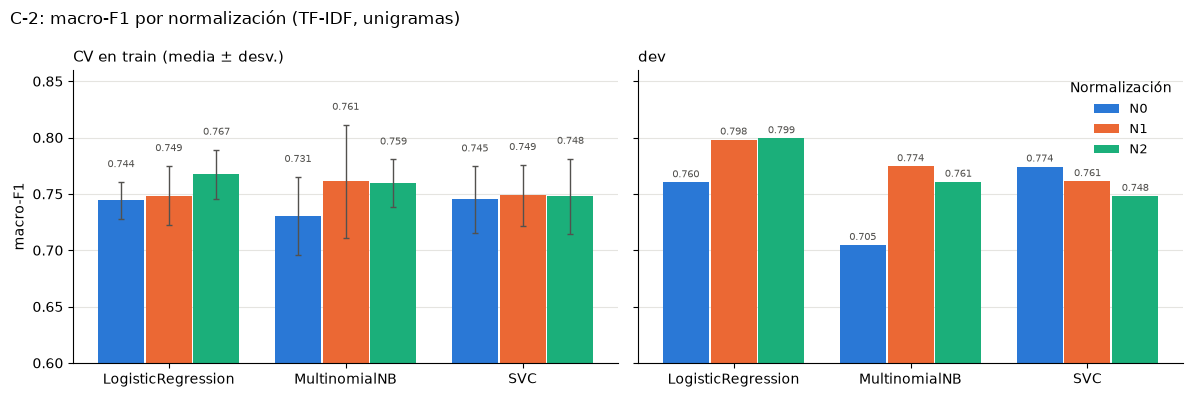

In [6]:
NORM_COLORS = {"N0": "#2a78d6", "N1": "#eb6834", "N2": "#1baf7a"}
models = list(dev.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
w = 0.26
for ax, table, title, err in [(axes[0], cv, "CV en train (media ± desv.)", std), (axes[1], dev, "dev", None)]:
    x = np.arange(len(models))
    for k, n in enumerate(config.NORMALIZATIONS):
        bars = ax.bar(x + (k - 1) * (w + 0.01), table[n], w, color=NORM_COLORS[n], label=n,
                      yerr=None if err is None else err[n],
                      error_kw=dict(ecolor="#52514e", lw=1, capsize=2))
        ax.bar_label(bars, fmt="%.3f", padding=2 if err is None else 9, fontsize=7, color="#52514e")
    ax.set_xticks(x, models)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(0.6, 0.86)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("macro-F1")
axes[1].legend(frameon=False, title="Normalización", fontsize=9, loc="upper right")
fig.suptitle("C-2: macro-F1 por normalización (TF-IDF, unigramas)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "C-2_macro_f1.png", dpi=150)
plt.show()

**Lectura de la gráfica**
- **N0 es el peor o empata con el peor en CV** para los tres modelos, como se esperaba.
- **LogisticRegression:** N1 y N2 empatan en dev (0.798 vs 0.799, la diferencia es menos de un documento). La CV sí distingue: N2 saca 0.767 y N1 0.749. → **N2**.
- **MultinomialNB:** N1 es el mejor en dev (+1.4 puntos sobre N2, ~1 documento), y en CV N1 y N2 empatan (0.761 vs 0.759). N0 queda claramente atrás: −7 puntos en dev y −3 en CV. → **N1**.
- **SVC:** en CV las tres normalizaciones son **prácticamente iguales** (0.745-0.749). En dev gana N0 por 1.3 puntos sobre N1, unos 2 documentos. → **N0** según la regla, pero es una victoria débil.

### Hiperparámetros elegidos en cada caso

In [7]:
res.pivot(index="model", columns="normalization", values="best_params")

normalization,N0,N1,N2
model,,,
LogisticRegression,C=10; min_df=2,C=0.1; min_df=2,C=1; min_df=1
MultinomialNB,alpha=0.1; min_df=2,alpha=0.1; min_df=2,alpha=0.5; min_df=2
SVC,C=10; min_df=1,C=1; min_df=1,C=1; min_df=1


- La regularización óptima **cambia con la normalización**. LR pasa de `C=10` con N0 a `C=0.1` con N1, y NB baja `alpha` a 0.1 con N0 y N1. Esto confirma que convenía ajustar los hiperparámetros en cada caso en lugar de copiar los de C-1.
- Con N0, LR y SVC prefieren `C=10` (menos regularización): el vocabulario es más grande y ruidoso, y necesitan más libertad para encontrar las palabras útiles entre tantas variantes.

## 4. F1 por clase en dev
¿La normalización ayuda a todas las clases por igual o solo a algunas?

In [8]:
rows = []
for r in results:
    t = per_class_table(r["y_dev"], r["y_pred"]).set_index("label")["f1"]
    rows.append({"model": r["model"], "normalization": r["normalization"], **t.round(3).to_dict()})
pd.DataFrame(rows).sort_values(["model", "normalization"]).set_index(["model", "normalization"])

cs.CL  cs.CV  cs.IR  cs.LG
model              normalization                            
LogisticRegression N0             0.684  0.778  0.789  0.789
                   N1             0.688  0.919  0.872  0.714
                   N2             0.703  0.833  0.872  0.789
MultinomialNB      N0             0.629  0.703  0.769  0.718
                   N1             0.722  0.824  0.821  0.732
                   N2             0.703  0.788  0.821  0.732
SVC                N0             0.732  0.765  0.789  0.811
                   N1             0.684  0.800  0.811  0.750
                   N2             0.700  0.765  0.778  0.750

## 5. Qué palabras usa el modelo: LogisticRegression con N0 vs N2
Términos con mayor coeficiente por clase. Sirve para ver si N0 aprovecha algo que N2 pierde (mayúsculas, plurales, siglas) o si solo agrega ruido.

In [9]:
def top_terms(result, k=8):
    pipe = result["search"].best_estimator_
    terms = pipe.named_steps["vec"].get_feature_names_out()
    coefs = pipe.named_steps["clf"].coef_
    return pd.DataFrame({c: [terms[i] for i in np.argsort(coefs[j])[::-1][:k]]
                         for j, c in enumerate(pipe.named_steps["clf"].classes_)})

by_key = {(r["model"], r["normalization"]): r for r in results}
for n in ["N0", "N2"]:
    print(f"LogisticRegression · {n}")
    display(top_terms(by_key[("LogisticRegression", n)]))

LogisticRegression · N0


,cs.CL,cs.CV,cs.IR,cs.LG
0,language,image,retrieval,$
1,reasoning,video,recommendation,forecasting
2,Language,visual,Retrieval,TRACE
3,LLMs,diffusion,query,attribution
4,models,reconstruction,item,learning
5,Task,motion,user,can
6,legal,spatial,relevance,which
7,Romanian,",",recommender,discovery


LogisticRegression · N2


,cs.CL,cs.CV,cs.IR,cs.LG
0,language,image,retrieval,$
1,reasoning,video,recommendation,forecasting
2,model,visual,query,environment
3,token,reconstruction,item,learn
4,task,object,user,attribution
5,speech,generation,document,gradient
6,prompt,scene,recommender,policy
7,legal,diffusion,system,network


**Lectura de los términos**
- Los términos principales son casi iguales con N0 y N2: *language*, *image*, *retrieval*, *forecasting*. Lo que distingue a cada área es su vocabulario temático, y eso sobrevive a cualquier normalización.
- **N0 desperdicia rasgos en duplicados** (`language`/`Language`, `retrieval`/`Retrieval`) y en ruido (la coma `,` aparece entre los términos de cs.CV, y `can` y `which` en cs.LG).
- **N2 aprovecha esos lugares para términos con contenido**: *token*, *speech*, *prompt* (CL); *object*, *scene* (CV); *document* (IR); *gradient*, *policy*, *network* (LG).
- `$` es el principal indicador de **cs.LG** con cualquier normalización: los abstracts de ML usan notación matemática en LaTeX (`$O(n)$`, `$\epsilon$`). Es una señal real del corpus, no un error.

## 6. Selección: la normalización que pasa a C-3

In [10]:
best = best_per_model(results)
sel = pd.DataFrame([{
    "model": m, "experiment_id": r["experiment_id"], "normalization": r["normalization"],
    "dev_macro_f1": round(r["dev_macro_f1"], 4), "cv_macro_f1": round(r["cv_macro_f1"], 4),
    "best_params": r["best_params"],
} for m, r in best.items()]).set_index("model")
sel

,experiment_id,normalization,dev_macro_f1,cv_macro_f1,best_params
model,,,,,
MultinomialNB,C07,N1,0.7745,0.7612,alpha=0.1; min_df=2
LogisticRegression,C02,N2,0.7993,0.7675,C=1; min_df=1
SVC,C06,N0,0.7742,0.7451,C=10; min_df=1


In [11]:
# Se anota la decisión en experiments.tsv
for m, r in best.items():
    annotate(r["experiment_id"], f"C-2: mejor normalización para {m} ({r['normalization']}); pasa a C-3")
load_experiments()[["experiment_id", "block", "normalization", "method", "hyperparameters", "cv_macro_f1", "dev_metric", "notes"]]

,experiment_id,block,normalization,method,hyperparameters,cv_macro_f1,dev_metric,notes
0,C01,C-1,N2,MultinomialNB,alpha=0.5; min_df=2,0.7594,macro_f1=0.7607; accuracy=0.7600,
1,C02,C-1,N2,LogisticRegression,C=1; min_df=1,0.7675,macro_f1=0.7993; accuracy=0.8000,C-2: mejor normalización para LogisticRegression (N2); pasa a C-3
2,C03,C-1,N2,SVC,C=1; min_df=1,0.7478,macro_f1=0.7481; accuracy=0.7467,
3,C04,C-2,N0,MultinomialNB,alpha=0.1; min_df=2,0.7306,macro_f1=0.7046; accuracy=0.7067,
4,C05,C-2,N0,LogisticRegression,C=10; min_df=2,0.7442,macro_f1=0.7602; accuracy=0.7600,
5,C06,C-2,N0,SVC,C=10; min_df=1,0.7451,macro_f1=0.7742; accuracy=0.7733,C-2: mejor normalización para SVC (N0); pasa a C-3
6,C07,C-2,N1,MultinomialNB,alpha=0.1; min_df=2,0.7612,macro_f1=0.7745; accuracy=0.7733,C-2: mejor normalización para MultinomialNB (N1); pasa a C-3
7,C08,C-2,N1,LogisticRegression,C=0.1; min_df=2,0.7486,macro_f1=0.7981; accuracy=0.8000,
8,C09,C-2,N1,SVC,C=1; min_df=1,0.7487,macro_f1=0.7613; accuracy=0.7600,


## 7. Conclusiones del bloque C-2

| Modelo | Normalización elegida | dev | CV | Pasa a C-3 |
|---|---|---|---|---|
| LogisticRegression | **N2** (C02) | 0.799 | 0.768 | ✔ |
| MultinomialNB | **N1** (C07) | 0.774 | 0.761 | ✔ |
| SVC | **N0** (C06) | 0.774 | 0.745 | ✔ |

1. **La hipótesis se cumple a medias.** Normalizar ayuda claramente a **NB** (+7 puntos en dev de N0 a N1) y a **LR** (+4 puntos de N0 a N2). A **SVC** no le cambia nada en CV.
2. **Por qué NB es el más sensible:** cuenta cada término como evidencia independiente. Con N0, la puntuación y los artículos dominan los conteos y la evidencia se reparte entre variantes (`Model`/`model`/`models`). LR y SVC aprenden pesos y pueden ignorar el ruido; SVC lo logra con `C=10`.
3. **N1 vs N2 es prácticamente un empate.** Ningún modelo muestra una diferencia mayor que ~1 documento en dev. Lematizar sobre N1 no aporta mucho más que quitar stopwords.
4. **Cada modelo prefiere una normalización distinta**, lo que justifica arrastrar la mejor de cada uno en lugar de imponer una sola.

**Limitación:** la elección de N0 para SVC se basa en 2 documentos de dev, y en CV las tres opciones empatan. Se respeta la regla de selección (macro-F1 en dev), pero en el informe debe reportarse como "la normalización no afecta a SVC". Si en C-3 o C-4 resultara inestable, una alternativa razonable sería N1, que en CV es igual y tiene un vocabulario menor.

**Siguiente, C-3:** binaria vs frecuencia vs TF-IDF, con NB+N1, LR+N2 y SVC+N0.

## 8. Registro en `experiments.tsv`
La celda de selección (sección 6) ya muestra el registro completo con las notas.